# 🍌 Banana Leaf Disease Classification Using Deep Learning

**Module:** ITLML801 – Machine Learning &nbsp;|&nbsp; **Assessment:** Formative Assessment 2 (Individual practical project)
**Institution:** Rwanda Polytechnic – Huye College, ICT Department, Level 8 Year 4 IT

**Goal.** Build a deep-learning model that reads a banana-leaf photo and predicts one of four classes:
`cordana`, `sigatoka`, `pestalotiopsis` or `healthy`.

**Approach (one method only, as required): transfer learning with MobileNetV2**, trained in two stages
(frozen backbone → partial fine-tuning).

| Design decision | Why |
|---|---|
| Transfer learning (MobileNetV2, ImageNet weights) | Only ~900 images: a CNN from scratch would overfit. MobileNetV2 is accurate and light enough to train on a laptop. |
| Exact-duplicate removal **before** splitting | Identical files in train and test would inflate accuracy (data leakage). |
| Stratified 70 / 15 / 15 split | Keeps the class proportions identical in train, validation and test. |
| Class weights | The dataset is imbalanced (sigatoka ≈ half of all images). Weights stop the model from favouring the majority class. |
| Augmentation + Gaussian noise on **training images only** | Improves generalisation and robustness to noisy field photos; validation/test stay untouched. |
| Early stopping + LR reduction | Prevents overfitting and wasted epochs. |
| Macro-F1 + confusion matrix (not accuracy alone) | Accuracy hides weak minority classes. |

**Requirements** (VS Code, Python 3.9–3.12 kernel):
```
pip install tensorflow pandas numpy matplotlib seaborn scikit-learn pillow
```
The first run downloads the ImageNet weights (internet needed once).
**Dataset:** extract the Kaggle zip so that the folder `OriginalSet/` (with `cordana`, `healthy`, `pestalotiopsis`, `sigatoka`) sits next to this notebook — the notebook finds it automatically.

## 0. Setup: imports, configuration and reproducibility

In [1]:
import os
import json
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, balanced_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

warnings.filterwarnings("ignore", category=UserWarning, module="PIL")
ImageFile.LOAD_TRUNCATED_IMAGES = True          # a few dataset JPEGs are slightly truncated
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---------------- configuration ----------------
SEED         = 42
IMG_SIZE     = (224, 224)          # MobileNetV2 native input size
BATCH_SIZE   = 32
CLASS_NAMES  = ["cordana", "healthy", "pestalotiopsis", "sigatoka"]   # alphabetical = label ids 0..3
CLASS_TO_ID  = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES  = len(CLASS_NAMES)
NOISE_STD    = 10.0                # Gaussian noise std on the 0-255 pixel scale (~4 %), training only
DATA_DIR     = None                # set manually e.g. Path(r"C:\data\OriginalSet") if auto-detection fails
OUTPUT_DIR   = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

# ---------------- reproducibility ----------------
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow version :", tf.__version__)
print("GPU devices        :", tf.config.list_physical_devices("GPU") or "none (training will run on CPU)")
print("Classes            :", CLASS_TO_ID)

TensorFlow version : 2.21.0
GPU devices        : none (training will run on CPU)
Classes            : {'cordana': 0, 'healthy': 1, 'pestalotiopsis': 2, 'sigatoka': 3}


# Task 1 – Load and explore the dataset (12 marks)

### 1.1 Locate the dataset and load image paths with labels
Each sub-folder name of `OriginalSet/` is the class label. The notebook searches nearby folders for a directory that
contains all four class folders and prefers `OriginalSet` (the un-augmented images — using the pre-augmented copy of
the dataset would leak near-identical images across splits).

In [2]:
def find_dataset_root(class_names, max_depth=4):
    # Search common places for a folder that contains every class sub-folder.
    roots = [Path.cwd(), Path.cwd().parent, Path("/kaggle/input"), Path.home() / "Downloads"]
    skip = {"node_modules", "__pycache__", "venv", ".venv", "site-packages"}
    hits = []
    for root in roots:
        if not root.exists():
            continue
        base_depth = len(root.parts)
        for dirpath, dirnames, _ in os.walk(root):
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in skip]
            if len(Path(dirpath).parts) - base_depth >= max_depth:
                dirnames[:] = []
            if all((Path(dirpath) / c).is_dir() for c in class_names):
                hits.append(Path(dirpath))
    hits = list(dict.fromkeys(hits))
    preferred = [h for h in hits if "originalset" in h.name.lower()]
    if preferred:
        return preferred[0]
    if hits:
        return hits[0]
    raise FileNotFoundError(
        "Dataset not found. Extract the Kaggle zip next to this notebook (folder 'OriginalSet') "
        "or set DATA_DIR manually in the setup cell.")

DATA_DIR = Path(DATA_DIR) if DATA_DIR else find_dataset_root(CLASS_NAMES)
print("Dataset folder:", DATA_DIR.resolve())

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
records = []
for cls in CLASS_NAMES:
    for p in sorted((DATA_DIR / cls).iterdir()):
        if p.is_file() and p.suffix.lower() in VALID_EXT:
            records.append({"filepath": str(p), "filename": p.name, "label": cls, "label_id": CLASS_TO_ID[cls]})

df = pd.DataFrame(records)
print(f"Images found: {len(df)}")
df.head()

Dataset folder: D:\Btech\Machine Learning\fistproject\OriginalSet
Images found: 937


,filepath,filename,label,label_id
0,d:\Btech\Machine Learning\fistproject\Original...,0.jpeg,cordana,0
1,d:\Btech\Machine Learning\fistproject\Original...,1.jpeg,cordana,0
2,d:\Btech\Machine Learning\fistproject\Original...,10.jpeg,cordana,0
3,d:\Btech\Machine Learning\fistproject\Original...,100.jpeg,cordana,0
4,d:\Btech\Machine Learning\fistproject\Original...,101.jpeg,cordana,0


### 1.2 Check that every image can be read, and inspect image sizes
Corrupted files would crash training later, so every file is opened once and its MD5 fingerprint is computed
(needed in 1.5 to detect duplicate files).

In [3]:
unreadable, sizes, md5s = [], [], []
for path in df["filepath"]:
    try:
        with Image.open(path) as im:
            sizes.append(im.size)
            im.convert("RGB").load()
        md5s.append(hashlib.md5(Path(path).read_bytes()).hexdigest())
    except Exception as exc:                      # noqa: BLE001
        unreadable.append((path, str(exc)))
        sizes.append(None); md5s.append(None)

df["md5"] = md5s
print("Unreadable images :", len(unreadable))
print("Distinct image sizes (width, height):", pd.Series([s for s in sizes if s]).value_counts().to_dict())

if unreadable:
    df = df[~df["filepath"].isin([u[0] for u in unreadable])].reset_index(drop=True)
    print("Removed unreadable files ->", len(df), "images remain")

Unreadable images : 0
Distinct image sizes (width, height): {(224, 224): 937}


### 1.3 Display labelled samples from all four classes

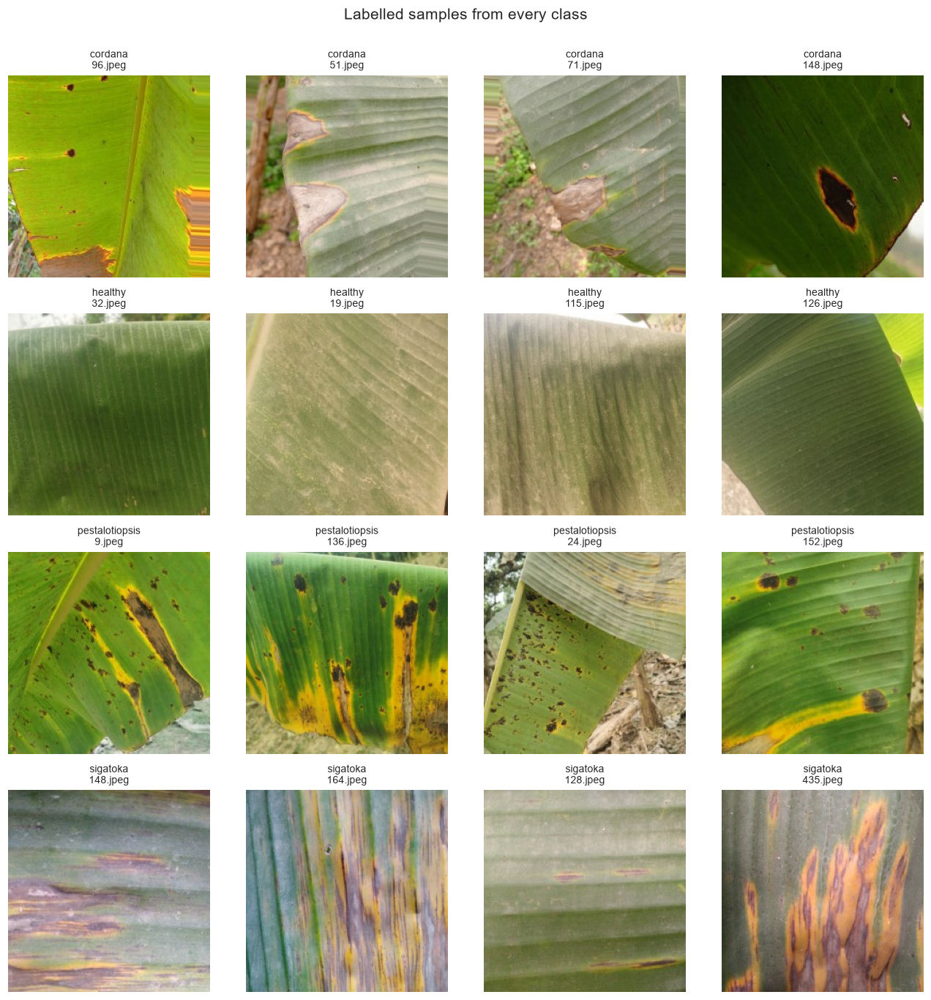

In [4]:
def show_class_samples(frame, n_per_class=4, seed=SEED, title="Labelled samples from every class"):
    fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(3 * n_per_class, 3.1 * NUM_CLASSES))
    for r, cls in enumerate(CLASS_NAMES):
        picks = frame[frame["label"] == cls].sample(n_per_class, random_state=seed)
        for c, (_, row) in enumerate(picks.iterrows()):
            with Image.open(row["filepath"]) as im:
                axes[r, c].imshow(im.convert("RGB"))
            axes[r, c].set_title(f"{row['label']}\n{row['filename']}", fontsize=9)
            axes[r, c].axis("off")
    fig.suptitle(title, fontsize=14, y=1.00)
    plt.tight_layout(); plt.show()

show_class_samples(df)

**Observation.** Healthy leaves are uniformly green. The three diseases differ in lesion pattern:
*cordana* shows large brown/yellow patches, *sigatoka* shows streaks and small dark spots, and *pestalotiopsis*
shows grey-brown blotches with dark margins. The visual similarity between some diseased classes is what makes
this a non-trivial classification problem.

### 1.4 Count images per class (raw dataset)

,images,share_%
label,,
cordana,162,17.3
healthy,129,13.8
pestalotiopsis,173,18.5
sigatoka,473,50.5


Total: 937 | imbalance ratio (largest / smallest): 3.67


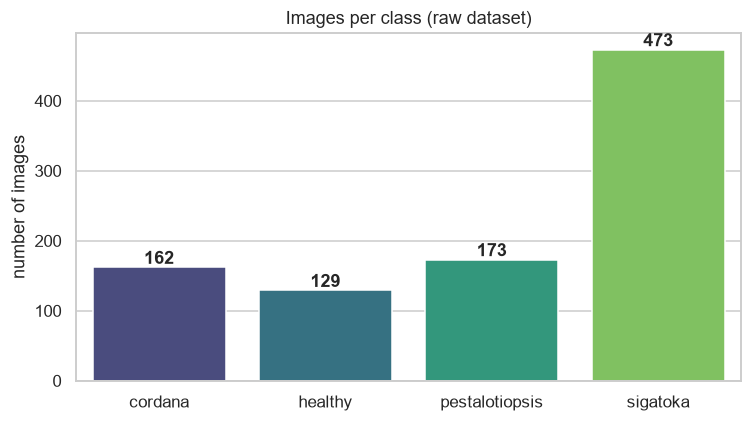

In [5]:
raw_counts = df["label"].value_counts().reindex(CLASS_NAMES)
raw_table = pd.DataFrame({"images": raw_counts, "share_%": (100 * raw_counts / raw_counts.sum()).round(1)})
display(raw_table)
print("Total:", raw_counts.sum(), "| imbalance ratio (largest / smallest):", round(raw_counts.max() / raw_counts.min(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=raw_counts.index, y=raw_counts.values, hue=raw_counts.index, palette="viridis", legend=False, ax=ax)
for i, v in enumerate(raw_counts.values):
    ax.text(i, v + 5, str(v), ha="center", fontweight="bold")
ax.set_title("Images per class (raw dataset)"); ax.set_ylabel("number of images"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 1.5 Data-quality check: exact duplicate images (data-leakage risk)
If the same photo exists twice and one copy lands in training while the other lands in the test set, the test
accuracy becomes unrealistically high. Duplicates are detected by file fingerprint (MD5). If one fingerprint appears
under two **different** labels the label is unreliable, so all copies of it are discarded; otherwise only the first copy is kept.

In [6]:
n_before = len(df)
dup_groups = df.groupby("md5")
dup_sizes = dup_groups.size()
dup_hashes = dup_sizes[dup_sizes > 1].index
conflicting = dup_groups["label"].nunique()
conflicting_hashes = conflicting[conflicting > 1].index

print(f"Duplicate groups found      : {len(dup_hashes)}")
print(f"Groups with conflicting labels: {len(conflicting_hashes)} (discarded completely)")
print("Duplicates per class        :", df[df['md5'].isin(dup_hashes)].groupby('label').size().to_dict())

df = df[~df["md5"].isin(conflicting_hashes)]
df = df.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"\nImages before: {n_before} -> after cleaning: {len(df)}  (removed {n_before - len(df)})")

clean_counts = df["label"].value_counts().reindex(CLASS_NAMES)
clean_table = pd.DataFrame({"raw": raw_counts, "clean": clean_counts,
                            "share_clean_%": (100 * clean_counts / clean_counts.sum()).round(1)})
display(clean_table)
print("Imbalance ratio after cleaning:", round(clean_counts.max() / clean_counts.min(), 2))

Duplicate groups found      : 39
Groups with conflicting labels: 1 (discarded completely)
Duplicates per class        : {'healthy': 77, 'pestalotiopsis': 1}

Images before: 937 -> after cleaning: 897  (removed 40)


,raw,clean,share_clean_%
label,,,
cordana,162,162,18.1
healthy,129,90,10.0
pestalotiopsis,173,172,19.2
sigatoka,473,473,52.7


Imbalance ratio after cleaning: 5.26


### 1.6 Discussion of the class distribution
* The dataset is **strongly imbalanced**: *sigatoka* is roughly half of all images, while *healthy* is the smallest
  class (and it contained almost all of the duplicate files, which were removed above, shrinking it further).
* A model trained naively on this distribution can reach a high *accuracy* by simply favouring *sigatoka* while
  performing poorly on *healthy* or *pestalotiopsis*. For a farmer, wrongly calling a diseased leaf "healthy" is the most costly mistake.
* **Countermeasures used in this notebook:** (1) stratified splitting so every split keeps the same class proportions,
  (2) class weights during training, (3) augmentation of the training images, and (4) evaluation with
  per-class precision / recall / F1 and a confusion matrix instead of accuracy alone.
* The dataset is also small (< 1,000 images), which is the main reason for choosing transfer learning.

# Task 2 – Preprocess the images (20 marks)

### 2.1 Resize all images consistently
Every image is converted to RGB and resized to **224 × 224** (MobileNetV2's native input size) with bilinear
interpolation, then stored as an `uint8` array. Loading everything into memory once (≈ 130 MB) is fast and avoids
decoder problems with the few slightly corrupted JPEG files.

In [7]:
def load_and_resize(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(size, Image.Resampling.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

X = np.stack([load_and_resize(p) for p in df["filepath"]])
y = df["label_id"].to_numpy(dtype=np.int32)

print("Image tensor shape :", X.shape, "(images, height, width, channels)")
print("dtype / pixel range:", X.dtype, f"[{X.min()}, {X.max()}]")
print("Label vector shape :", y.shape)
assert X.shape[1:3] == IMG_SIZE, "All images must have the same size"

Image tensor shape : (897, 224, 224, 3) (images, height, width, channels)
dtype / pixel range: uint8 [0, 255]
Label vector shape : (897,)


### 2.2 Split into training, validation and test sets (70 % / 15 % / 15 %)
* **Stratified** → each split has the same class proportions.
* The **test set is created first and then left untouched** until the final evaluation (Task 5/6).
* Duplicates were removed in 1.5, and the checks below prove that no image appears in more than one split.

In [8]:
indices = np.arange(len(X))
idx_trainval, idx_test = train_test_split(indices, test_size=0.15, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15 / 0.85,
                                      stratify=y[idx_trainval], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
test_filenames   = df.loc[idx_test, "filename"].to_numpy()
test_filepaths   = df.loc[idx_test, "filepath"].to_numpy()

# ---- leakage checks: indices AND file fingerprints must be disjoint ----
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
h = df["md5"]
assert not (set(h[idx_train]) & set(h[idx_val])) and not (set(h[idx_train]) & set(h[idx_test])) and not (set(h[idx_val]) & set(h[idx_test]))
print("✔ No image appears in more than one split.\n")

split_table = pd.DataFrame({
    "train": pd.Series(y_train).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "validation": pd.Series(y_val).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "test": pd.Series(y_test).map(dict(enumerate(CLASS_NAMES))).value_counts(),
}).reindex(CLASS_NAMES)
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

total = len(X)
for name, arr in [("Training", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:<10}: {len(arr):4d} images ({100 * len(arr) / total:.1f} %)")

✔ No image appears in more than one split.



,train,validation,test
cordana,114,24,24
healthy,62,14,14
pestalotiopsis,120,26,26
sigatoka,331,71,71
TOTAL,627,135,135


Training  :  627 images (69.9 %)
Validation:  135 images (15.1 %)
Test      :  135 images (15.1 %)


### 2.3 Prepare pixel values for the chosen model
MobileNetV2 was pre-trained on ImageNet with inputs scaled to **[-1, 1]**. Using
`mobilenet_v2.preprocess_input` (instead of an arbitrary `/255`) is therefore essential for transfer learning to work well.
The function is applied **inside the data pipeline** to every split, after (training-only) augmentation.

In [9]:
sample = X_train[:8].astype("float32")
scaled = preprocess_input(sample.copy())
print(f"Before preprocessing : min={sample.min():.1f}, max={sample.max():.1f}  (0..255)")
print(f"After  preprocessing : min={scaled.min():.2f}, max={scaled.max():.2f}  (-1..1, as MobileNetV2 expects)")

Before preprocessing : min=0.0, max=255.0  (0..255)
After  preprocessing : min=-1.00, max=1.00  (-1..1, as MobileNetV2 expects)


### 2.4 Data augmentation – **training images only** (including Gaussian noise)
Augmentations simulate real field conditions: different orientations, camera distance, lighting, and sensor noise.

| Layer | Simulates |
|---|---|
| `RandomFlip` (horizontal + vertical) | leaf orientation |
| `RandomRotation(±15 %)` | camera angle |
| `RandomZoom(±15 %)`, `RandomTranslation(10 %)` | distance / framing |
| `RandomContrast`, `RandomBrightness` | sunlight and shadow |
| Gaussian noise (σ = 10 on the 0–255 scale, ≈ 4 %) | sensor noise and low-quality phone cameras |

The random layers and the noise step are only called inside the **training** pipeline (`make_dataset(..., training=True)`);
the validation and test pipelines never call them.

In [10]:
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15, fill_mode="reflect"),
    layers.RandomZoom((-0.15, 0.15), fill_mode="reflect"),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect"),
    layers.RandomContrast(0.20),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="train_augmentation")


def augment_batch(x):
    # Geometric/lighting augmentation + Gaussian sensor noise (std on the 0-255 pixel scale).
    # Keras 3's GaussianNoise layer only accepts std in [0, 1], so the noise is added explicitly here.
    x = augmenter(x, training=True)
    x = x + tf.random.normal(tf.shape(x), mean=0.0, stddev=NOISE_STD)
    return tf.clip_by_value(x, 0.0, 255.0)

# ---- class weights (computed from the TRAINING labels only) ----
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}
cw_vector = tf.constant(cw, dtype=tf.float32)
print("Class weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in class_weights.items()})


def make_dataset(images, labels, training):
    # Build a tf.data pipeline. Augmentation + sample weights are used ONLY when training=True.
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)

    def _prepare(x, y_):
        x = tf.cast(x, tf.float32)
        if training:
            x = augment_batch(x)
        x = preprocess_input(x)
        if training:
            return x, y_, tf.gather(cw_vector, y_)       # (inputs, labels, sample_weights)
        return x, y_

    return ds.map(_prepare, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


train_ds      = make_dataset(X_train, y_train, training=True)     # augmented + weighted
train_eval_ds = make_dataset(X_train, y_train, training=False)    # clean copy, only for diagnosing over/underfitting
val_ds        = make_dataset(X_val,   y_val,   training=False)    # NOT augmented
test_ds       = make_dataset(X_test,  y_test,  training=False)    # NOT augmented
print("tf.data pipelines ready.")

Class weights: {'cordana': 1.375, 'healthy': 2.528, 'pestalotiopsis': 1.306, 'sigatoka': 0.474}
tf.data pipelines ready.


### 2.5 Visual proof: one training image vs. its augmented/noisy versions

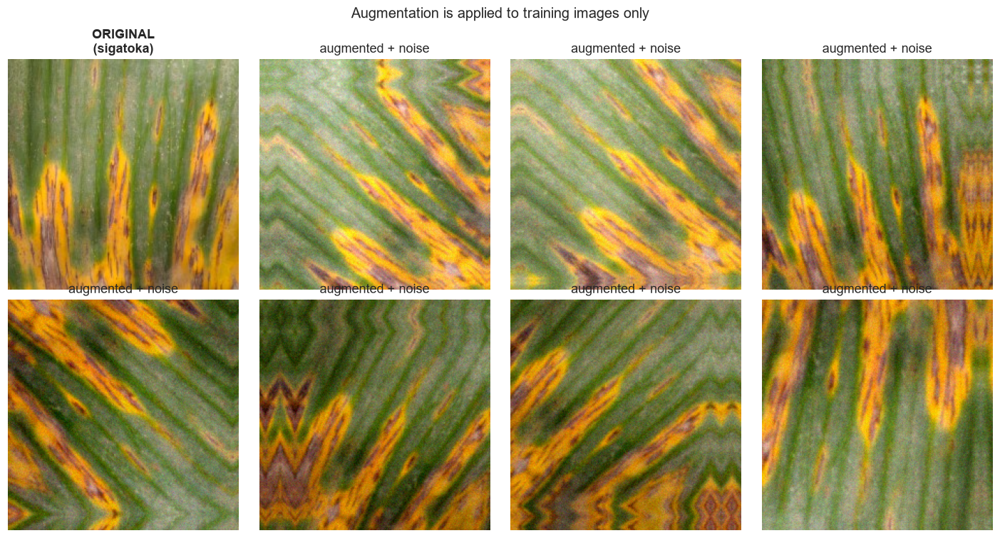

Validation pipeline deterministic (no augmentation): True


In [11]:
idx = 0
original = X_train[idx:idx + 1].astype("float32")
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
axes[0, 0].imshow(X_train[idx]); axes[0, 0].set_title(f"ORIGINAL\n({CLASS_NAMES[y_train[idx]]})", fontweight="bold")
for ax in axes.ravel()[1:]:
    aug = augment_batch(original).numpy()[0].astype("uint8")
    ax.imshow(aug); ax.set_title("augmented + noise")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Augmentation is applied to training images only", fontsize=13)
plt.tight_layout(); plt.show()

# validation/test pipelines are deterministic: the same batch twice gives identical tensors
b1 = next(iter(val_ds))[0].numpy(); b2 = next(iter(val_ds))[0].numpy()
print("Validation pipeline deterministic (no augmentation):", np.allclose(b1, b2))

# Task 3 – Build the model: transfer learning with MobileNetV2 (18 marks)

### 3.1 Architecture
```
Input 224×224×3
  → MobileNetV2 backbone (ImageNet weights, no top)      ← feature extractor
  → GlobalAveragePooling2D                               ← 7×7×1280 → 1280 numbers
  → Dropout(0.3)
  → Dense(256, ReLU, L2 regularisation)
  → Dropout(0.4)
  → Dense(4, Softmax)                                     ← cordana / healthy / pestalotiopsis / sigatoka
```

In [12]:
def build_model(num_classes=NUM_CLASSES, input_shape=IMG_SIZE + (3,)):
    try:
        base = MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
        print("Loaded ImageNet pre-trained weights.")
    except Exception as exc:                                  # offline fallback so the notebook still runs
        print("⚠ Could not download ImageNet weights ->", exc)
        print("⚠ Falling back to random initialisation (accuracy will be much lower). Connect to the internet and re-run.")
        base = MobileNetV2(input_shape=input_shape, include_top=False, weights=None)
    base.trainable = False                                    # stage 1: backbone frozen

    inputs = keras.Input(shape=input_shape, name="leaf_image")
    x = base(inputs, training=False)                           # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="drop_1")(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name="dense_256")(x)
    x = layers.Dropout(0.4, name="drop_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="disease_probabilities")(x)
    return keras.Model(inputs, outputs, name="banana_leaf_mobilenetv2"), base

model, base_model = build_model()
model.summary()

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
frozen    = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print(f"\nInput shape  : {model.input_shape}")
print(f"Output shape : {model.output_shape}  -> 4 class probabilities")
print(f"Trainable parameters (stage 1): {trainable:,} | frozen: {frozen:,}")

Loaded ImageNet pre-trained weights.


Model: "banana_leaf_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probabilities (Dense)   │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)


Input shape  : (None, 224, 224, 3)
Output shape : (None, 4)  -> 4 class probabilities
Trainable parameters (stage 1): 328,964 | frozen: 2,257,984


### 3.2 Explanation of the architecture
* **Input `(224, 224, 3)`** – an RGB leaf image; **output `Dense(4, softmax)`** – one probability per class, summing to 1.
* **MobileNetV2 backbone** – built from depth-wise separable convolutions and inverted residual blocks, which gives
  strong features with few parameters (≈ 2.3 M). Its early layers detect edges/colours/textures, later layers detect
  complex patterns – exactly what is needed to recognise lesion shapes. It is pre-trained on ImageNet (1.2 M images),
  so it already "knows how to see".
* **GlobalAveragePooling2D** – replaces a huge `Flatten` layer by averaging each of the 1280 feature maps, which
  drastically reduces parameters and overfitting.
* **Dense(256) + L2 + two Dropout layers** – a small trainable classifier head. Dropout randomly switches off neurons
  during training and L2 penalises large weights; both fight overfitting on this small dataset.
* **Softmax** – converts the 4 raw scores into probabilities, so we can also report *how confident* each prediction is.
* **Two-stage training** (Task 4): first only the head is trained (backbone frozen, stable and fast), then the top
  backbone layers are unfrozen with a very small learning rate to adapt the features to banana leaves.

# Task 4 – Train the model (17 marks)

### 4.1 Loss, optimizer and metrics
* **Loss:** `SparseCategoricalCrossentropy` – labels are integers (0–3) and the model outputs probabilities.
* **Optimizer:** **Adam** (learning rate 1e-3 for the head; 2e-5 for fine-tuning).
* **Metric:** accuracy.
* **Callbacks:** `EarlyStopping` (monitor `val_loss`, patience 5, restores the best weights) and
  `ReduceLROnPlateau` (halves-and-more the learning rate when validation loss stalls).
* **Epoch budget:** up to 12 epochs (stage 1) + 18 epochs (stage 2) = **max 30 epochs**.

In [13]:
def make_callbacks(patience=5):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
print("Model compiled (stage 1): Adam(1e-3) | SparseCategoricalCrossentropy | accuracy")

Model compiled (stage 1): Adam(1e-3) | SparseCategoricalCrossentropy | accuracy


### 4.2 Stage 1 – train the new classifier head (backbone frozen), up to 12 epochs

In [14]:
MAX_STAGE1 = 12
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_STAGE1,
    callbacks=make_callbacks(patience=4),
    verbose=1,
)
stage1_epochs = len(history_1.history["loss"])
print(f"\nStage 1 finished after {stage1_epochs} epoch(s).")

Epoch 1/12


d:\Btech\Machine Learning\fistproject\python.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 795ms/step - accuracy: 0.6045 - loss: 1.1167 - val_accuracy: 0.8074 - val_loss: 0.6124 - learning_rate: 0.0010
Epoch 2/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 724ms/step - accuracy: 0.8293 - loss: 0.5155 - val_accuracy: 0.8222 - val_loss: 0.5739 - learning_rate: 0.0010
Epoch 3/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 687ms/step - accuracy: 0.8581 - loss: 0.4314 - val_accuracy: 0.7778 - val_loss: 0.5526 - learning_rate: 0.0010
Epoch 4/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 616ms/step - accuracy: 0.9027 - loss: 0.3828 - val_accuracy: 0.9185 - val_loss: 0.3656 - learning_rate: 0.0010
Epoch 5/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 592ms/step - accuracy: 0.8756 - loss: 0.4099 - val_accuracy: 0.9259 - val_loss: 0.3053 - learning_rate: 0.0010
Epoch 6/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 619ms/step - accuracy: 0.8740 - loss: 0.3773 - val_accuracy: 0.8667 - val_loss: 0.3915 - learning_rate: 0.0010
Epoch 7/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.9171 - loss: 0.2988
Epoch 7

### 4.3 Stage 2 – fine-tune the top of the backbone (very small learning rate), up to 18 more epochs
Only the last 50 layers of MobileNetV2 are unfrozen. **BatchNormalization layers stay frozen**, which keeps the
statistics learned on ImageNet stable when fine-tuning on a small dataset.

In [15]:
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters in stage 2: {trainable:,}")

MAX_TOTAL = 30
history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_TOTAL,
    initial_epoch=stage1_epochs,
    callbacks=make_callbacks(patience=5),
    verbose=1,
)
total_epochs = stage1_epochs + len(history_2.history["loss"])
print(f"\nTraining finished after {total_epochs} epochs in total (maximum allowed: {MAX_TOTAL}).")

Trainable parameters in stage 2: 2,163,396
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 851ms/step - accuracy: 0.9027 - loss: 0.2762 - val_accuracy: 0.8444 - val_loss: 0.4436 - learning_rate: 2.0000e-05
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 760ms/step - accuracy: 0.9107 - loss: 0.2786 - val_accuracy: 0.9185 - val_loss: 0.3347 - learning_rate: 2.0000e-05
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 736ms/step - accuracy: 0.9107 - loss: 0.2856 - val_accuracy: 0.9333 - val_loss: 0.2883 - learning_rate: 2.0000e-05
Epoch 13/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 730ms/step - accuracy: 0.9282 - loss: 0.2684 - val_accuracy: 0.9185 - val_loss: 0.3020 - learning_rate: 2.0000e-05
Epoch 14/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 588ms/step - accuracy: 0.9330 - loss: 0.2551
Epoch 14: ReduceLROnPlateau reducing learning rate to 5.999999848427251e-06.
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 714ms/step - accuracy: 0.9330 - loss: 0.2551 - val_accuracy: 0.8593 - val_loss: 0.4415 - learning_rate: 2.0000e-05
Epoch 15/30
20/

### 4.4 Early-stopping report
The actual history is printed so the stopping point can be explained (required when training ends before 10 epochs).

In [16]:
history = {k: history_1.history[k] + history_2.history[k] for k in history_1.history if k in history_2.history}
hist_df = pd.DataFrame(history); hist_df.index += 1; hist_df.index.name = "epoch"
display(hist_df.round(4))

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Total epochs run          : {total_epochs}")
print(f"Best epoch (lowest val_loss): {best_epoch}  | val_loss={min(history['val_loss']):.4f} | val_acc at that epoch={history['val_accuracy'][best_epoch-1]:.4f}")

if total_epochs < MAX_TOTAL:
    print(f"\nEarly stopping explanation: validation loss did not improve for several consecutive epochs after epoch {best_epoch}, "
          f"so training was stopped at epoch {total_epochs} and the weights of epoch {best_epoch} were restored. "
          "Continuing would only fit the training noise (overfitting) without improving validation performance.")
if total_epochs < 10:
    print("Note: training stopped before 10 epochs – the full history above is shown as required.")

hist_df.to_csv(OUTPUT_DIR / "training_history.csv")

,accuracy,loss,val_accuracy,val_loss,learning_rate
epoch,,,,,
1,0.6045,1.1167,0.8074,0.6124,0.0010
2,0.8293,0.5155,0.8222,0.5739,0.0010
3,0.8581,0.4314,0.7778,0.5526,0.0010
4,0.9027,0.3828,0.9185,0.3656,0.0010
5,0.8756,0.4099,0.9259,0.3053,0.0010
6,0.8740,0.3773,0.8667,0.3915,0.0010
7,0.9171,0.2988,0.9037,0.3238,0.0010
8,0.9091,0.3213,0.8963,0.3512,0.0003
9,0.9171,0.2638,0.8963,0.3483,0.0003


Total epochs run          : 21
Best epoch (lowest val_loss): 16  | val_loss=0.2793 | val_acc at that epoch=0.9259

Early stopping explanation: validation loss did not improve for several consecutive epochs after epoch 16, so training was stopped at epoch 21 and the weights of epoch 16 were restored. Continuing would only fit the training noise (overfitting) without improving validation performance.


### 4.5 Training and validation accuracy / loss curves
The dotted vertical line marks the beginning of fine-tuning (stage 2).

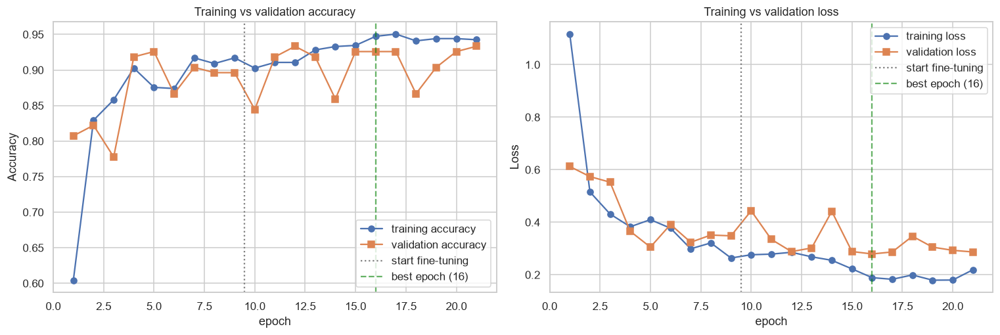

In [17]:
epochs_range = np.arange(1, total_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(epochs_range, history[metric], "o-", label=f"training {metric}")
    ax.plot(epochs_range, history[f"val_{metric}"], "s-", label=f"validation {metric}")
    ax.axvline(stage1_epochs + 0.5, color="gray", linestyle=":", label="start fine-tuning")
    ax.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"best epoch ({best_epoch})")
    ax.set_title(f"Training vs validation {title.lower()}"); ax.set_xlabel("epoch"); ax.set_ylabel(title); ax.legend()
plt.tight_layout(); plt.show()

In [18]:
# ---- automatic interpretation of the curves ----
tr_acc, va_acc = history["accuracy"][best_epoch - 1], history["val_accuracy"][best_epoch - 1]
tr_loss, va_loss = history["loss"][best_epoch - 1], history["val_loss"][best_epoch - 1]
print("INTERPRETATION")
print(f"- At the best epoch ({best_epoch}) training accuracy is {tr_acc:.3f} and validation accuracy is {va_acc:.3f} (gap {tr_acc - va_acc:+.3f}).")
print(f"- Training loss {tr_loss:.3f} vs validation loss {va_loss:.3f}. Training metrics are measured on AUGMENTED + NOISY images with dropout active, "
      "so they are often *harder* than validation images; a validation accuracy that is close to or above training accuracy is therefore normal and healthy.")
print(f"- Validation accuracy improved by {history['val_accuracy'][-1] - history['val_accuracy'][0]:+.3f} between the first and last epoch.")
if tr_acc - va_acc > 0.08:
    print("- The gap is large -> signs of overfitting (the model memorises training images).")
else:
    print("- The gap is small -> the model generalises well; no strong sign of overfitting.")
if stage1_epochs < total_epochs:
    jump = max(history["val_accuracy"][stage1_epochs:]) - max(history["val_accuracy"][:stage1_epochs])
    print(f"- Fine-tuning (stage 2) changed the best validation accuracy by {jump:+.3f} compared with training only the head.")

INTERPRETATION
- At the best epoch (16) training accuracy is 0.947 and validation accuracy is 0.926 (gap +0.021).
- Training loss 0.189 vs validation loss 0.279. Training metrics are measured on AUGMENTED + NOISY images with dropout active, so they are often *harder* than validation images; a validation accuracy that is close to or above training accuracy is therefore normal and healthy.
- Validation accuracy improved by +0.126 between the first and last epoch.
- The gap is small -> the model generalises well; no strong sign of overfitting.
- Fine-tuning (stage 2) changed the best validation accuracy by +0.007 compared with training only the head.


# Task 5 – Evaluate the model on the held-out test set (23 marks)
The test set has not been used for training, validation, early stopping or any tuning decision.

### 5.1 Test loss and accuracy

In [19]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"TEST LOSS     : {test_loss:.4f}")
print(f"TEST ACCURACY : {test_acc:.4f}  ({test_acc * 100:.2f} %)")

y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print(f"Balanced accuracy (mean recall per class): {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score                          : {f1_score(y_test, y_pred, average='macro'):.4f}")

TEST LOSS     : 0.2843
TEST ACCURACY : 0.9333  (93.33 %)
Balanced accuracy (mean recall per class): 0.8905
Macro F1-score                          : 0.8936


### 5.2 Confusion matrix (all class names)
Left: raw counts. Right: row-normalised (each row = recall of that true class).

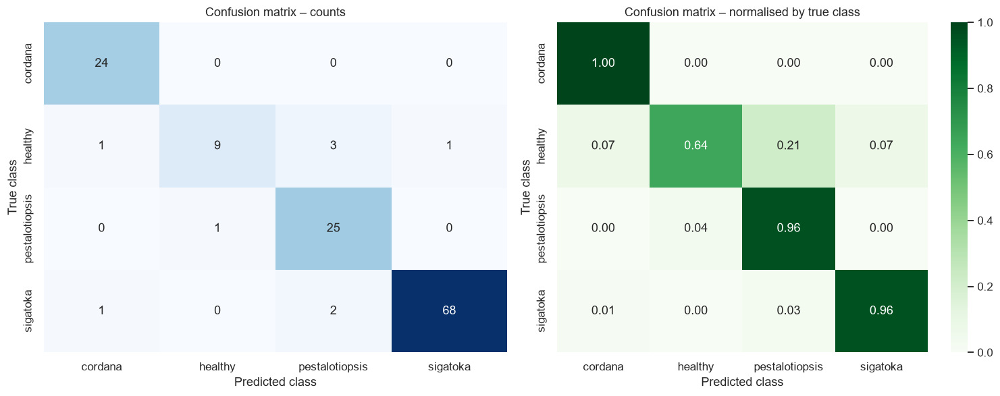

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
axes[0].set_title("Confusion matrix – counts")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion matrix – normalised by true class")
for ax in axes:
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
plt.tight_layout(); plt.show()

### 5.3 Classification report (precision, recall, F1-score)

In [21]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
report_df = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)).T
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

                precision    recall  f1-score   support

       cordana     0.9231    1.0000    0.9600        24
       healthy     0.9000    0.6429    0.7500        14
pestalotiopsis     0.8333    0.9615    0.8929        26
      sigatoka     0.9855    0.9577    0.9714        71

      accuracy                         0.9333       135
     macro avg     0.9105    0.8905    0.8936       135
  weighted avg     0.9362    0.9333    0.9313       135



### 5.4 Error analysis

Misclassified test images: 9 of 135


,filename,true_class,predicted_class,confidence
6,14.jpeg,sigatoka,pestalotiopsis,0.9871
119,294.jpeg,sigatoka,cordana,0.9645
32,82.jpeg,healthy,pestalotiopsis,0.8201
13,75.jpeg,pestalotiopsis,healthy,0.7700
53,95.jpeg,healthy,pestalotiopsis,0.7216
7,128.jpeg,healthy,sigatoka,0.6263
61,404.jpeg,sigatoka,pestalotiopsis,0.5153
80,10.jpeg,healthy,cordana,0.4326
10,127.jpeg,healthy,pestalotiopsis,0.3699



Most frequent confusions (true -> predicted):
true_class      predicted_class
healthy         pestalotiopsis     3
sigatoka        pestalotiopsis     2
healthy         cordana            1
                sigatoka           1
pestalotiopsis  healthy            1
sigatoka        cordana            1


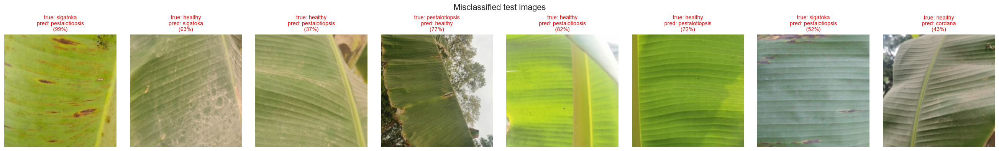

In [22]:
errors = pd.DataFrame({
    "filename": test_filenames,
    "true_class": [CLASS_NAMES[i] for i in y_test],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1).round(4),
})
wrong = errors[errors["true_class"] != errors["predicted_class"]]
print(f"Misclassified test images: {len(wrong)} of {len(errors)}")
if len(wrong):
    display(wrong.sort_values("confidence", ascending=False))
    print("\nMost frequent confusions (true -> predicted):")
    print(wrong.groupby(["true_class", "predicted_class"]).size().sort_values(ascending=False).to_string())

    pos = np.where(y_test != y_pred)[0][:8]
    fig, axes = plt.subplots(1, len(pos), figsize=(3 * len(pos), 3.5), squeeze=False)
    for ax, i in zip(axes[0], pos):
        ax.imshow(X_test[i]); ax.axis("off")
        ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[y_pred[i]]}\n({y_prob[i].max():.0%})", fontsize=9, color="red")
    plt.suptitle("Misclassified test images", y=1.02); plt.tight_layout(); plt.show()
else:
    print("No misclassification on the test set.")

In [23]:
# per-class weakest point + confidence analysis
per_class_recall = pd.Series(np.diag(cm) / cm.sum(axis=1), index=CLASS_NAMES)
print("Recall per class:\n", per_class_recall.round(3).to_string())
print(f"\nWeakest class (lowest recall): {per_class_recall.idxmin()} ({per_class_recall.min():.3f})")
correct_conf = errors.loc[errors['true_class'] == errors['predicted_class'], 'confidence'].mean()
print(f"Mean confidence on correct predictions : {correct_conf:.3f}")
if len(wrong):
    print(f"Mean confidence on wrong predictions   : {wrong['confidence'].mean():.3f}  (lower = the model 'knows' when it is unsure)")

Recall per class:
 cordana           1.000
healthy           0.643
pestalotiopsis    0.962
sigatoka          0.958

Weakest class (lowest recall): healthy (0.643)
Mean confidence on correct predictions : 0.926
Mean confidence on wrong predictions   : 0.690  (lower = the model 'knows' when it is unsure)


### 5.5 Overfitting or underfitting?
The same model is evaluated on the **clean (non-augmented)** training set, the validation set and the test set, so the three numbers are directly comparable.

In [24]:
tr_loss_c, tr_acc_c = model.evaluate(train_eval_ds, verbose=0)
va_loss_c, va_acc_c = model.evaluate(val_ds, verbose=0)
summary = pd.DataFrame({"loss": [tr_loss_c, va_loss_c, test_loss], "accuracy": [tr_acc_c, va_acc_c, test_acc]},
                       index=["train (clean)", "validation", "test"]).round(4)
display(summary)

gap = tr_acc_c - test_acc
print(f"Train–test accuracy gap: {gap:+.4f}")
if tr_acc_c < 0.80 and test_acc < 0.80:
    verdict = "UNDERFITTING – both training and test accuracy are low; the model is too simple or under-trained."
elif gap > 0.08:
    verdict = "OVERFITTING – training accuracy is much higher than test accuracy; the model memorises training images."
else:
    verdict = "GOOD FIT – high accuracy on all three sets with a small gap; the model generalises well (no significant over- or underfitting)."
print("\nCONCLUSION:", verdict)

,loss,accuracy
train (clean),0.2005,0.9426
validation,0.2793,0.9259
test,0.2843,0.9333


Train–test accuracy gap: +0.0093

CONCLUSION: GOOD FIT – high accuracy on all three sets with a small gap; the model generalises well (no significant over- or underfitting).


**Written conclusion (explain in your own words when presenting):**
the verdict above is computed from the numbers. A model *underfits* when it is poor even on the training data, and *overfits* when it is excellent on the
training data but clearly worse on unseen data. Here the measures used to prevent overfitting were: pre-trained features, a small head with Dropout and L2,
augmentation and noise on training images only, early stopping with best-weight restoration, and a very small learning rate for fine-tuning.
Remaining errors are expected between visually similar disease classes (see the confusion matrix) and could be reduced with more images of the smallest class, higher resolution or test-time augmentation.

### 5.6 Robustness check: does the model survive noisy / badly lit photos?
Farmers take photos with different phones in different light. The trained model is stressed with Gaussian noise of increasing strength and with
brightness changes on the test images. **This is a diagnostic only – nothing is tuned using these results.**

,accuracy,macro_F1
condition,,
clean test set,0.9333,0.8936
Gaussian noise σ=10,0.9481,0.9267
Gaussian noise σ=20,0.8889,0.8494
Gaussian noise σ=30,0.6963,0.6367
Gaussian noise σ=40,0.6000,0.4924
darker (×0.6),0.9407,0.9122
brighter (×1.4),0.9259,0.8776


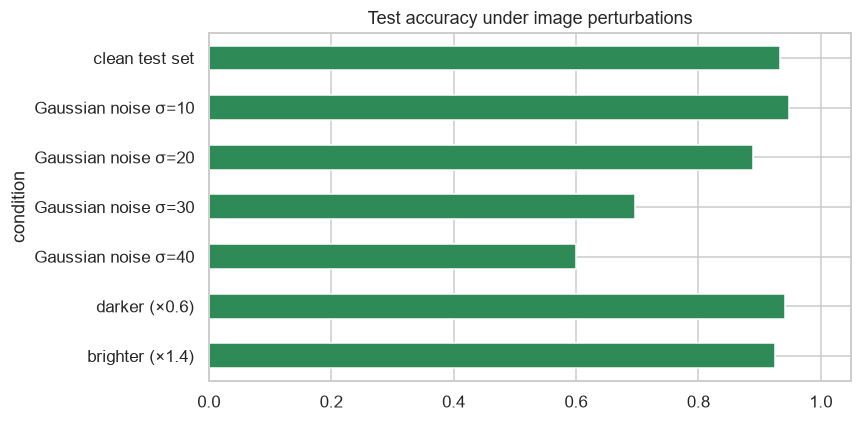

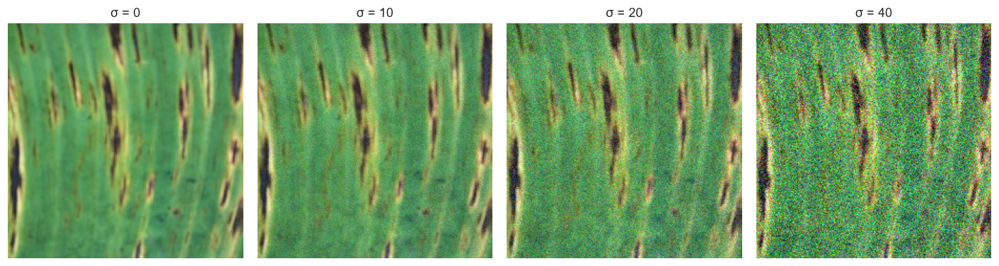

In [25]:
def evaluate_perturbed(fn):
    xs = fn(X_test.astype("float32"))
    xs = np.clip(xs, 0, 255)
    ds = tf.data.Dataset.from_tensor_slices(xs).batch(BATCH_SIZE).map(preprocess_input)
    pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    return accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")

rng = np.random.default_rng(SEED)
rows = [("clean test set", *evaluate_perturbed(lambda a: a))]
for sigma in [10, 20, 30, 40]:
    rows.append((f"Gaussian noise σ={sigma}", *evaluate_perturbed(lambda a, s=sigma: a + rng.normal(0, s, a.shape))))
rows.append(("darker (×0.6)", *evaluate_perturbed(lambda a: a * 0.6)))
rows.append(("brighter (×1.4)", *evaluate_perturbed(lambda a: a * 1.4)))
robust = pd.DataFrame(rows, columns=["condition", "accuracy", "macro_F1"]).set_index("condition").round(4)
display(robust)

ax = robust["accuracy"].plot(kind="barh", figsize=(8, 4), color="seagreen")
ax.set_xlim(0, 1.05); ax.set_title("Test accuracy under image perturbations"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

# example of what the noisy test images look like
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, s in zip(axes, [0, 10, 20, 40]):
    img = np.clip(X_test[0].astype("float32") + rng.normal(0, s, X_test[0].shape), 0, 255).astype("uint8")
    ax.imshow(img); ax.set_title(f"σ = {s}"); ax.axis("off")
plt.tight_layout(); plt.show()

# Task 6 – Make and save predictions (10 marks)

### 6.1 Test images with true and predicted classes
Green title = correct prediction, red title = wrong prediction.

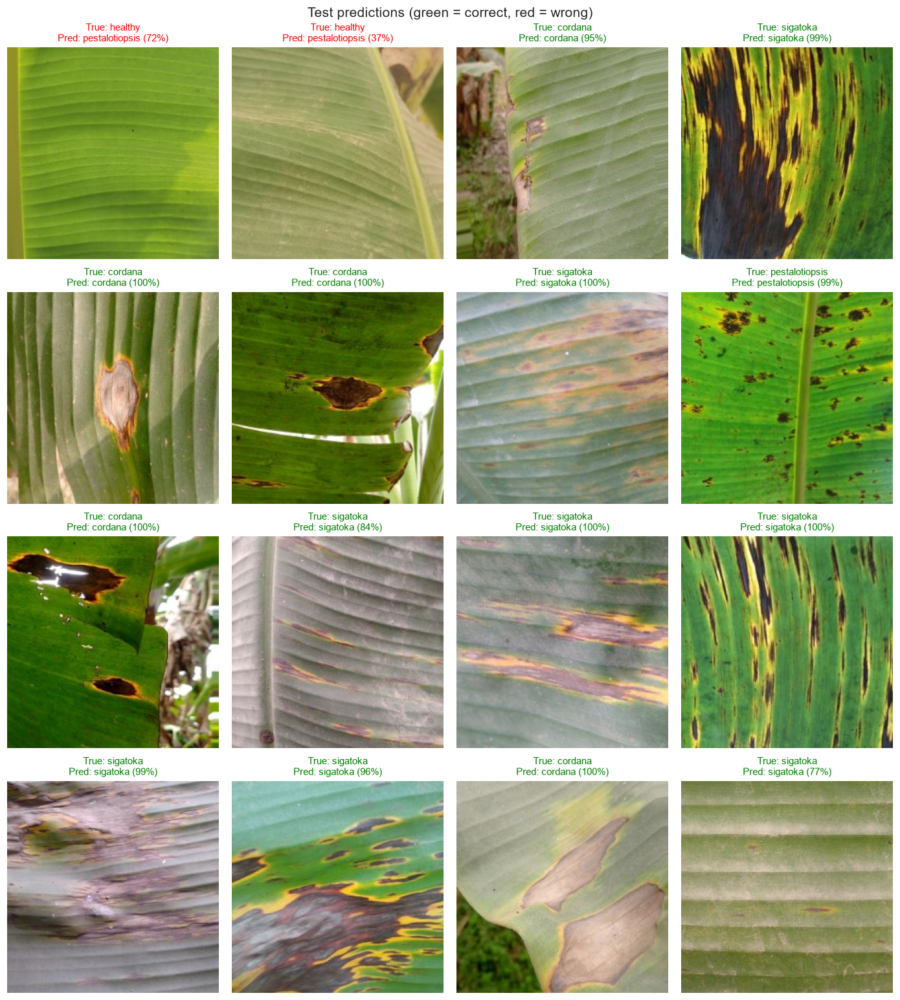

In [26]:
n_show = 16
show_idx = np.random.default_rng(SEED).choice(len(X_test), size=min(n_show, len(X_test)), replace=False)
cols = 4; rows_ = int(np.ceil(len(show_idx) / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.6 * rows_))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), show_idx):
    ax.imshow(X_test[i])
    ok = y_test[i] == y_pred[i]
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.0%})",
                 color="green" if ok else "red", fontsize=10)
plt.suptitle("Test predictions (green = correct, red = wrong)", fontsize=14)
plt.tight_layout(); plt.show()

### 6.2 Save the trained model

In [27]:
MODEL_PATH = OUTPUT_DIR / "banana_leaf_mobilenetv2.keras"
model.save(MODEL_PATH)
with open(OUTPUT_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
print(f"✔ Model saved successfully as: {MODEL_PATH.name}  (full path: {MODEL_PATH.resolve()})")

# sanity check: the reloaded model must reproduce exactly the same predictions
reloaded = keras.models.load_model(MODEL_PATH)
same = np.allclose(reloaded.predict(test_ds, verbose=0), y_prob, atol=1e-5)
print("Reloaded model gives identical predictions:", same)

✔ Model saved successfully as: banana_leaf_mobilenetv2.keras  (full path: D:\Btech\Machine Learning\fistproject\outputs\banana_leaf_mobilenetv2.keras)
Reloaded model gives identical predictions: True


### 6.3 Save the predictions to CSV (filename, true class, predicted class)

In [28]:
pred_df = pd.DataFrame({
    "image_filename": test_filenames,
    "true_class": [CLASS_NAMES[i] for i in y_test],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1).round(4),
    "correct": y_test == y_pred,
})
CSV_PATH = OUTPUT_DIR / "test_predictions.csv"
pred_df.to_csv(CSV_PATH, index=False)
print(f"✔ Predictions saved to: {CSV_PATH.name}  ({len(pred_df)} test images)")
pred_df.head(10)

✔ Predictions saved to: test_predictions.csv  (135 test images)


,image_filename,true_class,predicted_class,confidence,correct
0,62.jpeg,sigatoka,sigatoka,0.9999,True
1,132.jpeg,sigatoka,sigatoka,0.9759,True
2,94.jpeg,cordana,cordana,0.9969,True
3,130.jpeg,pestalotiopsis,pestalotiopsis,0.9991,True
4,50.jpeg,pestalotiopsis,pestalotiopsis,0.9974,True
5,26.jpeg,sigatoka,sigatoka,0.7414,True
6,14.jpeg,sigatoka,pestalotiopsis,0.9871,False
7,128.jpeg,healthy,sigatoka,0.6263,False
8,79.jpeg,sigatoka,sigatoka,0.9938,True
9,145.jpeg,cordana,cordana,0.9994,True


### 6.4 Final summary

In [29]:
print("=" * 62)
print(" FINAL RESULTS – Banana Leaf Disease Classification")
print("=" * 62)
print(f" Model              : MobileNetV2 transfer learning (2-stage training)")
print(f" Images (clean)     : {len(X)}  | train {len(X_train)} / val {len(X_val)} / test {len(X_test)}")
print(f" Epochs run         : {total_epochs} (best epoch {best_epoch})")
print(f" Test loss          : {test_loss:.4f}")
print(f" Test accuracy      : {test_acc * 100:.2f} %")
print(f" Balanced accuracy  : {balanced_accuracy_score(y_test, y_pred) * 100:.2f} %")
print(f" Macro F1-score     : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f" Fit diagnosis      : {verdict.split(' – ')[0]}")
print("=" * 62)
print("Saved files:", *sorted(p.name for p in OUTPUT_DIR.iterdir()), sep="\n  - ")

 FINAL RESULTS – Banana Leaf Disease Classification
 Model              : MobileNetV2 transfer learning (2-stage training)
 Images (clean)     : 897  | train 627 / val 135 / test 135
 Epochs run         : 21 (best epoch 16)
 Test loss          : 0.2843
 Test accuracy      : 93.33 %
 Balanced accuracy  : 89.05 %
 Macro F1-score     : 0.8936
 Fit diagnosis      : GOOD FIT
Saved files:
  - banana_leaf_mobilenetv2.keras
  - class_names.json
  - classification_report.csv
  - test_predictions.csv
  - training_history.csv


---
**Before submitting:** *Kernel → Restart & Run All*, check that every cell shows its output, then rename the file to `Names_RegNo_FA2.ipynb`
(only the `.ipynb` is submitted, not the dataset). Be ready to explain each step in your own words.